# AquaSentinel — Review 2 (R in Google Colab)

This notebook follows the IDS Review 2 requirements: dataset inspection, preprocessing, EDA, classification, evaluation, feature explanation and reproducible documentation.

### Important
- The key prediction results are calculated from the dataset. No accuracy or graph result is hard-coded.
- LIME is installed in a separate optional cell so a LIME installation issue does not block data cleaning, EDA or model evaluation.

## Cell 1 — Set up R and the R notebook bridge

Run once per fresh runtime. If R and `rpy2` are already available, this cell checks them and skips unnecessary installation.

In [ ]:
import os, shutil, subprocess, sys

if shutil.which("R") is None or shutil.which("Rscript") is None:
    print("R is not installed. Installing R...")
    subprocess.run(["bash", "-lc", "apt-get -qq update && apt-get -qq install -y r-base r-base-dev"], check=True)
else:
    print("R is already installed; skipping system installation.")

try:
    import rpy2.ipython
    print("rpy2 is already installed.")
except Exception:
    print("Installing rpy2...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rpy2"], check=True)

print("Setup check complete.")

R is already installed; skipping system installation.
rpy2 is already installed.
Setup check complete.


## Cell 2 — Enable R cells

This is a **Python magic cell**, so do not add `%%R` here. Keep the following R code in separate cells.

In [ ]:
%load_ext rpy2.ipython

## Cell 3 — Confirm R is working

In [ ]:
%%R
cat("R is working. Version:", R.version.string, "\n")

R is working. Version: R version 4.6.1 (2026-06-24) 


## Cell 4 — Make sure the CSV is available

This cell checks `/content` first. It will only open the upload chooser if the CSV is missing. If it asks for a file, select **`water_potability.csv`** (not the ZIP or notebook).

In [ ]:
from pathlib import Path
from google.colab import files

csv_path = Path("/content/water_potability.csv")
if csv_path.exists():
    print("Dataset already exists — no upload needed:", csv_path)
else:
    print("Dataset is not in this runtime yet. Choose water_potability.csv.")
    uploaded = files.upload()
    csv_candidates = [Path("/content") / name for name in uploaded.keys() if name.lower().endswith(".csv")]
    exact = [p for p in csv_candidates if p.name.lower() == "water_potability.csv"]
    if exact:
        exact[0].rename(csv_path)
    elif len(csv_candidates) == 1:
        csv_candidates[0].rename(csv_path)

if csv_path.exists():
    print("READY:", csv_path.name, "—", csv_path.stat().st_size, "bytes")
else:
    raise FileNotFoundError("No CSV file found. Upload the Kaggle water_potability.csv file.")

Dataset is not in this runtime yet. Choose water_potability.csv.


Saving water_potability.csv to water_potability.csv
READY: water_potability.csv — 525187 bytes


## Cell 5 — Install only the core R packages

The main workflow needs only `ggplot2` for charts and `randomForest` for the comparison model. Logistic Regression uses base R. This keeps installation lighter. LIME is handled separately later.

In [ ]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))
core_packages <- c("ggplot2", "randomForest")
for (pkg in core_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    cat("Installing", pkg, "...\n")
    tryCatch(
      install.packages(pkg, dependencies = NA),
      error = function(e) cat("Installation error for", pkg, ":", conditionMessage(e), "\n")
    )
  }
  if (requireNamespace(pkg, quietly = TRUE)) {
    cat("READY:", pkg, "\n")
  } else {
    stop(paste("Required package could not be installed:", pkg, ". See the messages above."))
  }
}

READY: ggplot2 
Installing randomForest ...
READY: randomForest 


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/randomForest_4.7-1.2.tar.gz'
Content type 'application/x-gzip' length 81974 bytes (80 KB)
downloaded 80 KB


The downloaded source packages are in
	‘/tmp/RtmpVKXdYo/downloaded_packages’


## Cell 6 — Load and inspect the dataset

This cell uses base R for inspection, so it will not fail just because an optional plotting/explainability package is absent.

In [ ]:
%%R
csv_path <- "/content/water_potability.csv"
if (!file.exists(csv_path)) stop("CSV not found at /content/water_potability.csv. Run Cell 4 first.")
water_raw <- read.csv(csv_path, stringsAsFactors = FALSE, check.names = TRUE)

cat("DATASET DIMENSIONS\n")
cat("Rows:", nrow(water_raw), " | Columns:", ncol(water_raw), "\n\n")
cat("COLUMN NAMES\n")
print(names(water_raw))
cat("\nDATA STRUCTURE\n")
str(water_raw)
cat("\nMISSING VALUES BY COLUMN\n")
print(colSums(is.na(water_raw)))
cat("\nEXACT DUPLICATE ROWS:", sum(duplicated(water_raw)), "\n")
if ("Potability" %in% names(water_raw)) {
  cat("\nPOTABILITY COUNTS (0 = non-potable, 1 = potable)\n")
  print(table(water_raw$Potability, useNA = "ifany"))
} else {
  stop("Expected Potability target column was not found. Check that you uploaded the correct CSV.")
}
cat("\nSUMMARY STATISTICS\n")
print(summary(water_raw))

DATASET DIMENSIONS
Rows: 3276  | Columns: 10 

COLUMN NAMES
 [1] "ph"              "Hardness"        "Solids"          "Chloramines"    
 [5] "Sulfate"         "Conductivity"    "Organic_carbon"  "Trihalomethanes"
 [9] "Turbidity"       "Potability"     

DATA STRUCTURE
'data.frame':	3276 obs. of  10 variables:
 $ ph             : num  NA 3.72 8.1 8.32 9.09 ...
 $ Hardness       : num  205 129 224 214 181 ...
 $ Solids         : num  20791 18630 19910 22018 17979 ...
 $ Chloramines    : num  7.3 6.64 9.28 8.06 6.55 ...
 $ Sulfate        : num  369 NA NA 357 310 ...
 $ Conductivity   : num  564 593 419 363 398 ...
 $ Organic_carbon : num  10.4 15.2 16.9 18.4 11.6 ...
 $ Trihalomethanes: num  87 56.3 66.4 100.3 32 ...
 $ Turbidity      : num  2.96 4.5 3.06 4.63 4.08 ...
 $ Potability     : int  0 0 0 0 0 0 0 0 0 0 ...

MISSING VALUES BY COLUMN
             ph        Hardness          Solids     Chloramines         Sulfate 
            491               0               0               0  

## Cell 7 — Clean the data and create train/validation/test splits

- Remove exact duplicates and rows with missing/invalid target labels.
- Keep the predictor missing values for the missingness analysis.
- Make a stratified 70%/15%/15% split.
- Impute predictor missing values using **training-set medians only** to avoid using test data to prepare the model.

In [ ]:
%%R
set.seed(42)
water <- water_raw
water$Potability <- suppressWarnings(as.integer(as.character(water$Potability)))
water <- water[!duplicated(water), , drop = FALSE]
water <- water[!is.na(water$Potability) & water$Potability %in% c(0L, 1L), , drop = FALSE]

features <- setdiff(names(water), "Potability")
for (v in features) water[[v]] <- suppressWarnings(as.numeric(water[[v]]))

# Stratified indices so both classes are represented across the splits.
set.seed(42)
class_indices <- split(seq_len(nrow(water)), water$Potability)
train_idx <- integer(0); valid_idx <- integer(0); test_idx <- integer(0)
for (cl in names(class_indices)) {
  ids <- sample(class_indices[[cl]])
  n <- length(ids)
  n_train <- max(1, floor(0.70 * n))
  n_valid <- max(1, floor(0.15 * n))
  if (n_train + n_valid >= n) n_valid <- max(1, n - n_train - 1)
  train_idx <- c(train_idx, ids[seq_len(n_train)])
  if (n_valid > 0) valid_idx <- c(valid_idx, ids[(n_train + 1):(n_train + n_valid)])
  test_start <- n_train + n_valid + 1
  if (test_start <= n) test_idx <- c(test_idx, ids[test_start:n])
}

train_raw <- water[train_idx, , drop = FALSE]
valid_raw <- water[valid_idx, , drop = FALSE]
test_raw  <- water[test_idx, , drop = FALSE]

medians <- vapply(train_raw[features], function(x) median(x, na.rm = TRUE), numeric(1))
medians[!is.finite(medians)] <- 0
impute_with_train_medians <- function(df) {
  for (v in features) {
    missing <- is.na(df[[v]])
    if (any(missing)) df[[v]][missing] <- medians[[v]]
  }
  df
}
train_data <- impute_with_train_medians(train_raw)
valid_data <- impute_with_train_medians(valid_raw)
test_data  <- impute_with_train_medians(test_raw)

cat("Rows after duplicate/target checks:", nrow(water), "\n")
cat("Training rows:", nrow(train_data), "\n")
cat("Validation rows:", nrow(valid_data), "\n")
cat("Test rows:", nrow(test_data), "\n")
cat("\nMissing values after imputation (train / validation / test):\n")
cat(sum(is.na(train_data)), "/", sum(is.na(valid_data)), "/", sum(is.na(test_data)), "\n")
cat("\nTraining class distribution:\n")
print(table(train_data$Potability))

Rows after duplicate/target checks: 3276 
Training rows: 2292 
Validation rows: 490 
Test rows: 494 

Missing values after imputation (train / validation / test):
0 / 0 / 0 

Training class distribution:

   0    1 
1398  894 


## Cell 8 — EDA: Potability class distribution

The chart is generated from the actual dataset. Use the printed counts to describe the class balance.

            Class Count
1 Not potable (0)  1998
2     Potable (1)  1278


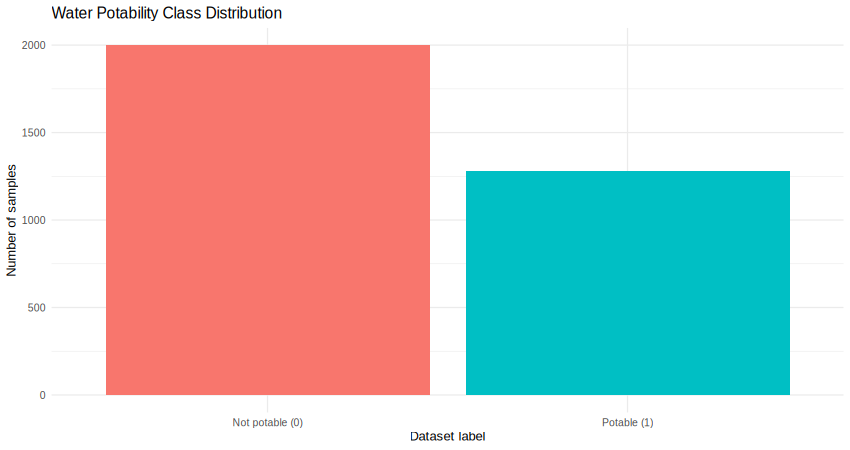

In [ ]:
%%R -w 850 -h 450
library(ggplot2)
class_df <- as.data.frame(table(factor(water$Potability, levels = c(0, 1))))
names(class_df) <- c("Potability", "Count")
class_df$Class <- factor(class_df$Potability, levels = c("0", "1"), labels = c("Not potable (0)", "Potable (1)"))
print(ggplot(class_df, aes(x = Class, y = Count, fill = Class)) +
  geom_col(show.legend = FALSE) +
  labs(title = "Water Potability Class Distribution", x = "Dataset label", y = "Number of samples") +
  theme_minimal(base_size = 13))
print(class_df[, c("Class", "Count")])

## Cell 9 — EDA: Missing values by feature

This uses the dataset before imputation, so the missing counts are genuine data-quality information.

         Feature Missing
         Sulfate     781
              ph     491
 Trihalomethanes     162
        Hardness       0
          Solids       0
     Chloramines       0
    Conductivity       0
  Organic_carbon       0
       Turbidity       0
      Potability       0


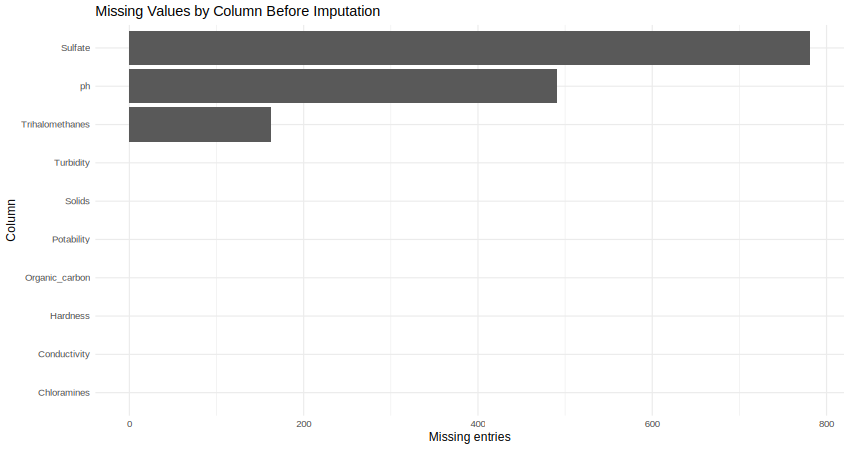

In [ ]:
%%R -w 850 -h 450
missing_df <- data.frame(Feature = names(water), Missing = as.integer(colSums(is.na(water))))
missing_df <- missing_df[order(missing_df$Missing), ]
print(ggplot(missing_df, aes(x = reorder(Feature, Missing), y = Missing)) +
  geom_col() + coord_flip() +
  labs(title = "Missing Values by Column Before Imputation", x = "Column", y = "Missing entries") +
  theme_minimal(base_size = 12))
print(missing_df[order(-missing_df$Missing), ], row.names = FALSE)

## Cell 10 — EDA: pH distribution by potability class

The values with missing pH are omitted from this plot only; they remain part of the dataset and are handled in preprocessing.

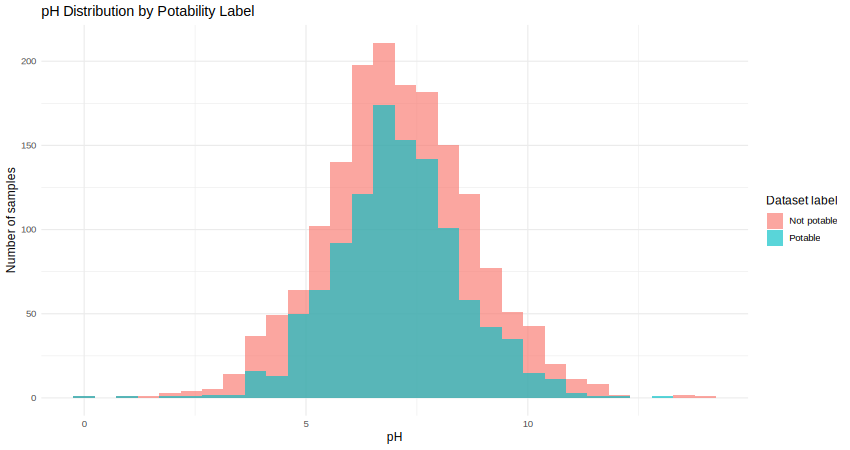

In [ ]:
%%R -w 850 -h 450
if (!"ph" %in% names(water)) stop("The expected pH column 'ph' was not found.")
ph_df <- water[!is.na(water$ph) & !is.na(water$Potability), , drop = FALSE]
ph_df$PotabilityLabel <- factor(ph_df$Potability, levels = c(0, 1), labels = c("Not potable", "Potable"))
print(ggplot(ph_df, aes(x = ph, fill = PotabilityLabel)) +
  geom_histogram(bins = 30, alpha = 0.65, position = "identity") +
  labs(title = "pH Distribution by Potability Label", x = "pH", y = "Number of samples", fill = "Dataset label") +
  theme_minimal(base_size = 12))

## Cell 11 — EDA: Correlation heatmap

This uses `ggplot2` only; it does not require the `corrplot` package.

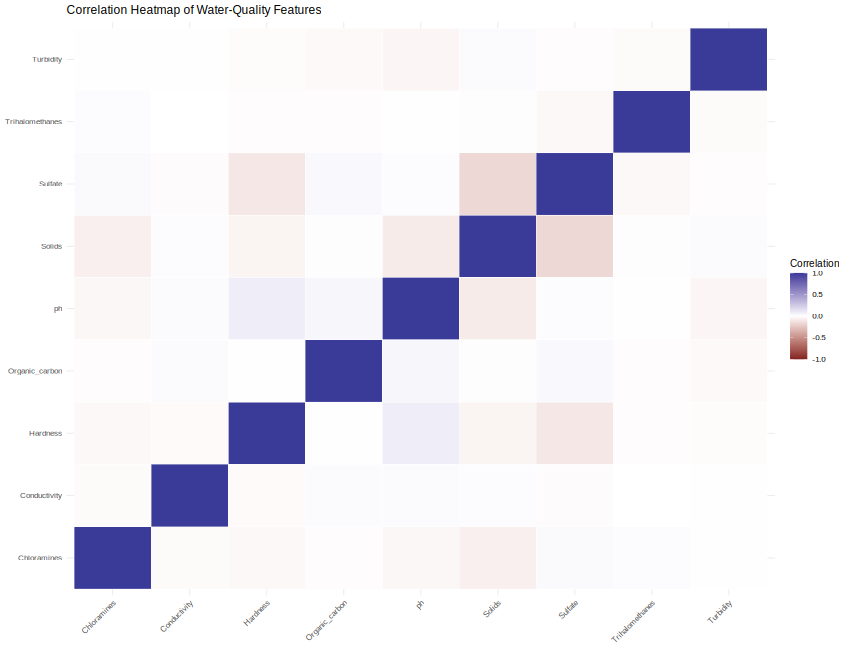

In [ ]:
%%R -w 850 -h 650
cor_data <- water[features]
cor_matrix <- cor(cor_data, use = "pairwise.complete.obs")
cor_long <- as.data.frame(as.table(cor_matrix), stringsAsFactors = FALSE)
names(cor_long) <- c("Feature1", "Feature2", "Correlation")
print(ggplot(cor_long, aes(x = Feature1, y = Feature2, fill = Correlation)) +
  geom_tile(color = "white") +
  scale_fill_gradient2(limits = c(-1, 1), midpoint = 0) +
  labs(title = "Correlation Heatmap of Water-Quality Features", x = NULL, y = NULL, fill = "Correlation") +
  theme_minimal(base_size = 10) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)))

## Cell 12 — Train Logistic Regression

Logistic Regression is the primary syllabus-aligned classification model. It is fitted only on the training split.

In [ ]:
%%R
logit_formula <- as.formula(paste("Potability ~", paste(features, collapse = " + ")))
logit_model <- glm(logit_formula, data = train_data, family = binomial())
logit_valid_prob <- as.numeric(predict(logit_model, newdata = valid_data[, features, drop = FALSE], type = "response"))
logit_valid_prob <- pmin(pmax(logit_valid_prob, 0), 1)
cat("Logistic Regression trained successfully.\n")
cat("Validation probability range:", paste(round(range(logit_valid_prob, na.rm = TRUE), 4), collapse = " to "), "\n")
print(summary(logit_model)$coefficients)

Logistic Regression trained successfully.
Validation probability range: 0.2923 to 0.559 
                     Estimate   Std. Error    z value   Pr(>|z|)
(Intercept)     -5.770012e-01 7.339490e-01 -0.7861598 0.43177389
ph               2.666143e-02 2.947425e-02  0.9045668 0.36569494
Hardness        -1.506581e-03 1.315192e-03 -1.1455216 0.25199315
Solids           8.469004e-06 4.946058e-06  1.7122735 0.08684628
Chloramines      3.742495e-02 2.725454e-02  1.3731642 0.16970132
Sulfate         -1.251223e-04 1.206053e-03 -0.1037453 0.91737148
Conductivity     1.530275e-04 5.287138e-04  0.2894335 0.77224969
Organic_carbon  -2.080954e-02 1.301715e-02 -1.5986245 0.10990405
Trihalomethanes -3.106755e-03 2.736315e-03 -1.1353794 0.25621640
Turbidity        6.533466e-02 5.509676e-02  1.1858167 0.23569468


## Cell 13 — Train Random Forest for comparison

Random Forest is a comparison model. We compare both models on the validation split; the held-out test split is saved for the final evaluation.

In [ ]:
%%R
library(randomForest)
rf_train <- train_data
rf_train$Potability <- factor(rf_train$Potability, levels = c(0, 1))
set.seed(42)
rf_model <- randomForest(Potability ~ ., data = rf_train, ntree = 300, importance = TRUE)
rf_valid_prob_matrix <- predict(rf_model, newdata = valid_data[, features, drop = FALSE], type = "prob")
rf_valid_prob <- as.numeric(rf_valid_prob_matrix[, "1"])
rf_valid_prob <- pmin(pmax(rf_valid_prob, 0), 1)
cat("Random Forest trained successfully with 300 trees.\n")

Random Forest trained successfully with 300 trees.


randomForest 4.7-1.2
Type rfNews() to see new features/changes/bug fixes.

Attaching package: ‘randomForest’

The following object is masked from ‘package:ggplot2’:

    margin



## Cell 14 — Compare validation performance and select a model

The model is selected using **validation ROC-AUC**, not test performance. A threshold of 0.5 is used for the displayed classification metrics.

In [ ]:
%%R
safe_div <- function(a, b) if (b == 0) 0 else a / b
auc_rank <- function(actual, prob) {
  y <- as.integer(as.character(actual))
  n1 <- sum(y == 1, na.rm = TRUE); n0 <- sum(y == 0, na.rm = TRUE)
  if (n1 == 0 || n0 == 0) return(NA_real_)
  r <- rank(prob, ties.method = "average")
  (sum(r[y == 1], na.rm = TRUE) - n1 * (n1 + 1) / 2) / (n1 * n0)
}
metrics_for <- function(actual, prob, threshold = 0.5) {
  y <- as.integer(as.character(actual))
  pred <- ifelse(prob >= threshold, 1L, 0L)
  tp <- sum(pred == 1 & y == 1, na.rm = TRUE)
  tn <- sum(pred == 0 & y == 0, na.rm = TRUE)
  fp <- sum(pred == 1 & y == 0, na.rm = TRUE)
  fn <- sum(pred == 0 & y == 1, na.rm = TRUE)
  precision <- safe_div(tp, tp + fp)
  recall <- safe_div(tp, tp + fn)
  f1 <- safe_div(2 * precision * recall, precision + recall)
  data.frame(Accuracy = safe_div(tp + tn, tp + tn + fp + fn),
             Precision = precision, Recall = recall, F1 = f1,
             ROC_AUC = auc_rank(y, prob), TP = tp, TN = tn, FP = fp, FN = fn)
}

valid_logit <- metrics_for(valid_data$Potability, logit_valid_prob)
valid_rf <- metrics_for(valid_data$Potability, rf_valid_prob)
validation_comparison <- rbind(
  cbind(Model = "Logistic Regression", valid_logit),
  cbind(Model = "Random Forest", valid_rf)
)
validation_comparison$ROC_AUC <- as.numeric(validation_comparison$ROC_AUC)
print(validation_comparison, row.names = FALSE)

auc_values <- as.numeric(validation_comparison$ROC_AUC)
auc_values[!is.finite(auc_values)] <- -Inf
selected_name <- validation_comparison$Model[which.max(auc_values)]
if (!is.finite(max(auc_values))) stop("Could not calculate validation ROC-AUC; check class labels in the dataset.")
selected_model <- if (selected_name == "Random Forest") rf_model else logit_model
selected_test_prob <- NULL
cat("\nSelected model based on validation ROC-AUC:", selected_name, "\n")

               Model  Accuracy Precision      Recall         F1   ROC_AUC TP
 Logistic Regression 0.6122449 1.0000000 0.005235602 0.01041667 0.4365512  1
       Random Forest 0.6224490 0.5319149 0.261780105 0.35087719 0.6272129 50
  TN FP  FN
 299  0 190
 255 44 141

Selected model based on validation ROC-AUC: Random Forest 


## Cell 15 — Final evaluation on the held-out test set

These are the test results. Do not tune the model based on this test output.

In [ ]:
%%R
if (selected_name == "Random Forest") {
  selected_test_prob <- as.numeric(predict(rf_model, newdata = test_data[, features, drop = FALSE], type = "prob")[, "1"])
} else {
  selected_test_prob <- as.numeric(predict(logit_model, newdata = test_data[, features, drop = FALSE], type = "response"))
}
selected_test_prob <- pmin(pmax(selected_test_prob, 0), 1)
test_metrics <- metrics_for(test_data$Potability, selected_test_prob, threshold = 0.5)
cat("SELECTED MODEL:", selected_name, "\n")
cat("TEST METRICS (probability threshold = 0.5)\n")
print(round(test_metrics, 4), row.names = FALSE)
actual_class <- factor(test_data$Potability, levels = c(0, 1), labels = c("Not potable", "Potable"))
predicted_class <- factor(ifelse(selected_test_prob >= 0.5, 1, 0), levels = c(0, 1), labels = c("Not potable", "Potable"))
confusion_table <- table(Actual = actual_class, Predicted = predicted_class)
cat("\nCONFUSION MATRIX\n")
print(confusion_table)

SELECTED MODEL: Random Forest 
TEST METRICS (probability threshold = 0.5)
 Accuracy Precision Recall     F1 ROC_AUC TP  TN FP  FN
   0.6721    0.6505 0.3472 0.4527   0.691 67 265 36 126

CONFUSION MATRIX
             Predicted
Actual        Not potable Potable
  Not potable         265      36
  Potable             126      67


## Cell 16 — Plot the confusion matrix and ROC curve

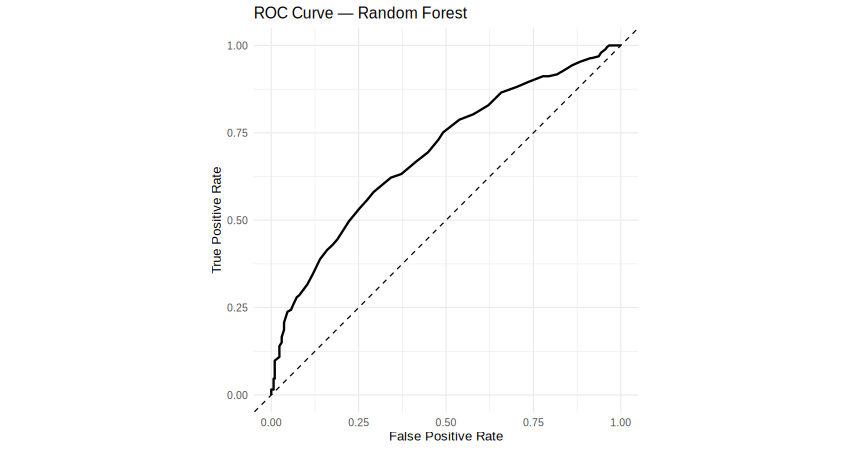

In [ ]:
%%R -w 850 -h 450
cm_plot_data <- as.data.frame(confusion_table)
print(ggplot(cm_plot_data, aes(x = Predicted, y = Actual, fill = Freq)) +
  geom_tile(color = "white") + geom_text(aes(label = Freq), size = 6) +
  labs(title = paste("Test Confusion Matrix —", selected_name), x = "Predicted class", y = "Actual class", fill = "Count") +
  theme_minimal(base_size = 13))

thresholds <- seq(0, 1, by = 0.01)
y_test <- as.integer(as.character(test_data$Potability))
roc_df <- do.call(rbind, lapply(thresholds, function(th) {
  pred <- ifelse(selected_test_prob >= th, 1L, 0L)
  tp <- sum(pred == 1 & y_test == 1)
  tn <- sum(pred == 0 & y_test == 0)
  fp <- sum(pred == 1 & y_test == 0)
  fn <- sum(pred == 0 & y_test == 1)
  data.frame(Threshold = th, FPR = safe_div(fp, fp + tn), TPR = safe_div(tp, tp + fn))
}))
roc_df <- roc_df[order(roc_df$FPR, roc_df$TPR), ]
print(ggplot(roc_df, aes(x = FPR, y = TPR)) +
  geom_line(linewidth = 1.1) + geom_abline(slope = 1, intercept = 0, linetype = "dashed") +
  coord_equal() + xlim(0, 1) + ylim(0, 1) +
  labs(title = paste("ROC Curve —", selected_name), x = "False Positive Rate", y = "True Positive Rate") +
  theme_minimal(base_size = 13))

## Cell 17 — Random Forest feature importance

Feature importance indicates which features the Random Forest uses most for its splits. It is not proof that those features cause potability.

         Feature Importance
        Hardness   140.4810
         Sulfate   139.1784
              ph   138.5288
          Solids   124.0075
     Chloramines   120.8472
 Trihalomethanes   108.1516
    Conductivity   107.2200
  Organic_carbon   106.8609
       Turbidity   104.6249


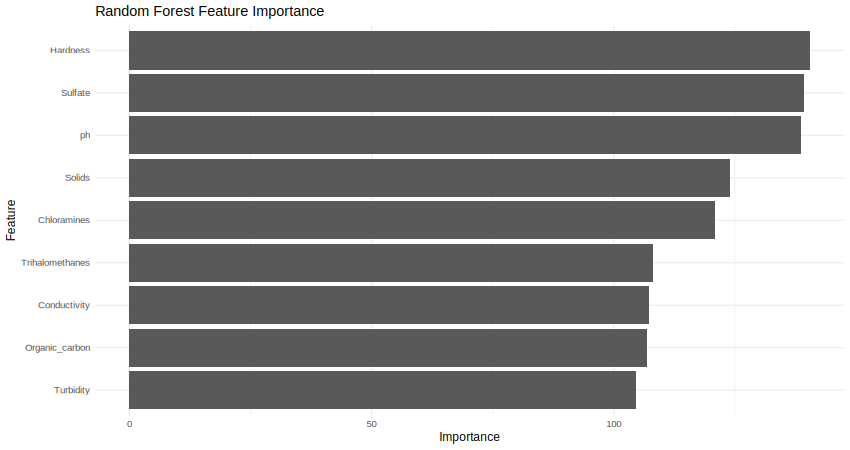

In [ ]:
%%R -w 850 -h 450
imp <- randomForest::importance(rf_model)
if (is.matrix(imp) && "MeanDecreaseGini" %in% colnames(imp)) {
  imp_values <- imp[, "MeanDecreaseGini"]
} else if (is.matrix(imp)) {
  imp_values <- imp[, ncol(imp)]
} else {
  imp_values <- imp
}
importance_df <- data.frame(Feature = names(imp_values), Importance = as.numeric(imp_values))
importance_df <- importance_df[order(importance_df$Importance, decreasing = TRUE), ]
print(ggplot(importance_df, aes(x = reorder(Feature, Importance), y = Importance)) +
  geom_col() + coord_flip() +
  labs(title = "Random Forest Feature Importance", x = "Feature", y = "Importance") +
  theme_minimal(base_size = 12))
print(importance_df, row.names = FALSE)

## Cell 18 — Install LIME separately (optional if CRAN installation fails)

Run this after all core outputs are finished. If the package cannot be installed, the rest of the notebook remains usable. Do not report a LIME result unless the next cell actually generates one.

In [ ]:
%%R
options(repos = c(CRAN = "https://cloud.r-project.org"))
if (!requireNamespace("lime", quietly = TRUE)) {
  cat("Attempting to install LIME and its required dependencies...\n")
  tryCatch(
    install.packages("lime", dependencies = NA),
    error = function(e) cat("LIME installation error:", conditionMessage(e), "\n")
  )
}
if (requireNamespace("lime", quietly = TRUE)) {
  cat("READY: lime\n")
} else {
  cat("LIME is not installed in this runtime. Core EDA/model results remain available; do not claim a LIME plot was generated.\n")
}

Attempting to install LIME and its required dependencies...
READY: lime


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependencies ‘iterators’, ‘foreach’, ‘shape’, ‘assertthat’, ‘glmnet’, ‘gower’, ‘RcppEigen’

trying URL 'https://cloud.r-project.org/src/contrib/iterators_1.0.14.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/foreach_1.5.2.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/shape_1.4.6.1.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/assertthat_0.2.1.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/glmnet_5.1.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/gower_1.0.2.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/RcppEigen_0.3.4.0.2.tar.gz'
trying URL 'https://cloud.r-project.org/src/contrib/lime_0.5.4.tar.gz'

The downloaded source packages are in
	‘/tmp/RtmpVKXdYo/downloaded_packages’


## Cell 19 — Explain one prediction using LIME

This cell is protected: if LIME is unavailable or a model adapter fails, it prints the reason rather than stopping the entire notebook. A successful plot is the actual LIME explanation for the held-out sample.

Predicted class: 0 
Probability of potable class: 0.1833 
# A tibble: 5 × 13
  model_type    case  label label_prob model_r2 model_intercept model_prediction
  <chr>         <chr> <chr>      <dbl>    <dbl>           <dbl>            <dbl>
1 classificati… 968   0          0.817    0.134           0.495            0.586
2 classificati… 968   0          0.817    0.134           0.495            0.586
3 classificati… 968   0          0.817    0.134           0.495            0.586
4 classificati… 968   0          0.817    0.134           0.495            0.586
5 classificati… 968   0          0.817    0.134           0.495            0.586
# ℹ 6 more variables: feature <chr>, feature_value <dbl>, feature_weight <dbl>,
#   feature_desc <chr>, data <list>, prediction <list>


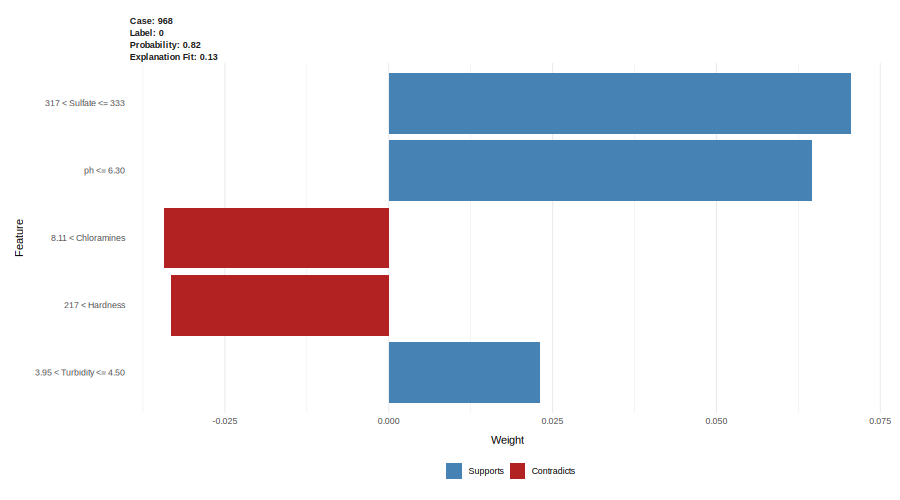

In [ ]:
%%R -w 900 -h 500

# AquaSentinel: LIME explanation of the predicted class
library(lime)

# Wrap Random Forest as a classification model
lime_model <- lime::as_classifier(
  rf_model,
  labels = c("0", "1")
)

# Create the explainer using training features
lime_explainer <- lime::lime(
  x = train_data[, features, drop = FALSE],
  model = lime_model
)

# Select one held-out test sample
lime_case <- test_data[1, features, drop = FALSE]

# Get Random Forest probabilities for this sample
case_prob <- predict(
  rf_model,
  newdata = lime_case,
  type = "prob"
)

prob_potable <- as.numeric(case_prob[1, "1"])

# Explain the class predicted at threshold 0.5
predicted_label <- if (prob_potable >= 0.5) "1" else "0"

cat("Predicted class:", predicted_label, "\n")
cat("Probability of potable class:", round(prob_potable, 4), "\n")

# Generate local explanation
lime_result <- lime::explain(
  x = lime_case,
  explainer = lime_explainer,
  labels = predicted_label,
  n_features = 5,
  n_permutations = 500
)

# Display graph and explanation table
print(lime::plot_features(lime_result))
print(lime_result)

## Cell 20 — Review 2 summary: report real outputs only

In [ ]:
%%R
cat("AQUASENTINEL — REVIEW 2 SUMMARY\n")
cat("Rows after removing exact duplicates/invalid target labels:", nrow(water), "\n")
cat("Train / validation / test rows:", nrow(train_data), "/", nrow(valid_data), "/", nrow(test_data), "\n")
cat("Selected model by validation ROC-AUC:", selected_name, "\n")
cat("Test accuracy:", round(test_metrics$Accuracy, 4), "\n")
cat("Test precision:", round(test_metrics$Precision, 4), "\n")
cat("Test recall:", round(test_metrics$Recall, 4), "\n")
cat("Test F1:", round(test_metrics$F1, 4), "\n")
cat("Test ROC-AUC:", round(test_metrics$ROC_AUC, 4), "\n")
cat("\nInterpret scores together: accuracy alone can hide poor detection of one class.\n")
cat("These are dataset-label predictions, not certification of drinking-water safety.\n")

## Cell 21 — Save a compact results CSV

This saves the validation comparison and final held-out test metrics in `/content`. It does not require downloading a separate ZIP to see the results, but the files can be downloaded if needed.

In [ ]:
%%R
write.csv(validation_comparison, "/content/aquasentinel_validation_comparison.csv", row.names = FALSE)
write.csv(test_metrics, "/content/aquasentinel_test_metrics.csv", row.names = FALSE)
cat("Saved:\n/content/aquasentinel_validation_comparison.csv\n/content/aquasentinel_test_metrics.csv\n")

## Review 2 talking points

After running the notebook, explain the results using your actual values:

1. **Dataset:** report the dimensions and the measured missing values shown above.
2. **Cleaning:** explain that missing predictor values were imputed using medians calculated on the training split only.
3. **EDA:** state one observation that is directly visible in each chart.
4. **Model comparison:** explain why Logistic Regression is the syllabus-aligned baseline and why Random Forest is a comparison model.
5. **Evaluation:** report the held-out test metrics; discuss recall and F1 as well as accuracy.
6. **Explainability:** only claim a LIME explanation if Cell 19 generated the plot successfully.
7. **Limitation:** this model predicts the dataset's label. It does not replace laboratory or regulatory drinking-water testing.

For the final submission, your guidelines also call for a concise R Markdown report and simple version control. This notebook gives you reproducible code and outputs; you can preserve named versions or export the analysis into the final R Markdown document after the results are confirmed.